<a href="https://colab.research.google.com/github/Steve-Rodrigues/Machine-Learning/blob/main/Chapter2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

We will be creating a ML model of housing prices in California to predict the median housing price in any district, given all our metrics. We are going to be using a data set that includes data from each block group in California. Block groups typicall has a population of 600-3,000 people (our districts).

Loading the data we will use

In [87]:
from pathlib import Path
import pandas as pd
import tarfile
import urllib.request



def load_housing_data():
    tarball_path = Path("datasets/housing.tgz")
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, tarball_path)
        with tarfile.open(tarball_path) as housing_tarball:
            housing_tarball.extractall(path="datasets")
    return pd.read_csv(Path("datasets/housing/housing.csv"))

housing_data = load_housing_data()
housing_data.head()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [88]:
housing_data.describe()
housing_data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [89]:
import matplotlib.pyplot as plt

housing_data['ocean_proximity'].value_counts()


,count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


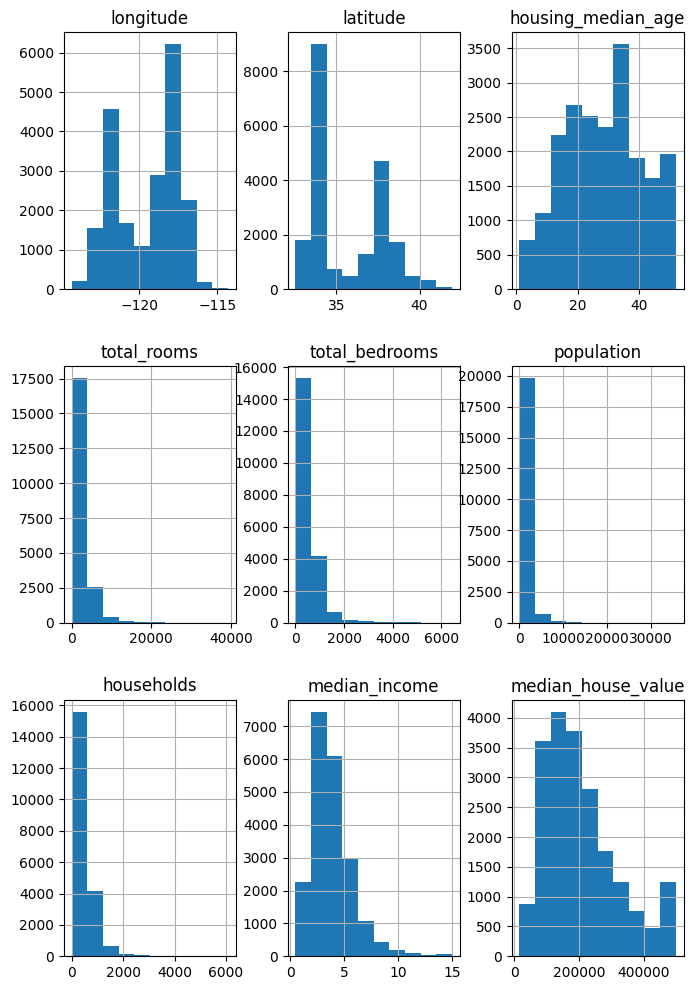

In [90]:
housing_data.hist(bins=10, figsize=(8,12))
plt.show()


In [91]:
housing_data.corr(numeric_only=True)['median_house_value'].sort_values(ascending=False) #checking the correlation between the house value and the numeric cols.
#there seems to be a strong correlation between the income and house value.

,median_house_value
median_house_value,1.000000
median_income,0.688075
total_rooms,0.134153
housing_median_age,0.105623
households,0.065843
total_bedrooms,0.049686
population,-0.024650
longitude,-0.045967
latitude,-0.144160


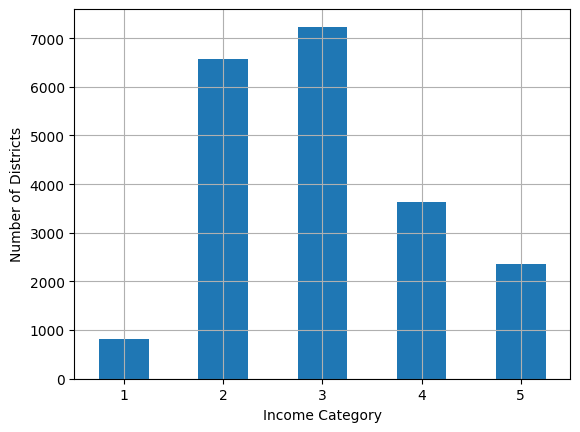

In [92]:
#Need to perform stratified sampling on the median_income column so the model is trained on the same proporiton as the population
#So creating helper col to put the incomes in buckets to stratify from since we cant stratify from continous variables (they would all be unique)
import numpy as np
housing_data['income_cat'] = pd.cut(housing_data['median_income'],
                                    bins=[0,1.5,3.0,4.5,6.0,np.inf],
                                    labels=[1,2,3,4,5])
cat_counts=housing_data['income_cat'].value_counts().sort_index() #proporitoin of each income group-- most are in the middle class
cat_counts.plot.bar(rot=0,grid=True)
plt.xlabel('Income Category')
plt.ylabel('Number of Districts')
plt.show()


Splitting the dataframe into train and test dataframes using the new column for the stratified sampling. It will give each dataframe the same proportion of incomes as the population has. Since we pass in the whole data frame, it will return the full train and test dataframe to us

In [93]:
from sklearn.model_selection import train_test_split

train_data, test_data = train_test_split(
    housing_data, test_size=0.2, stratify=housing_data['income_cat'], random_state=11
)

Test to see if the proportions of the income cateogries were kept correctly

In [94]:
test_data['income_cat'].value_counts() / len(test_data)
train_data['income_cat'].value_counts()/ len(train_data)

,count
income_cat,
3,0.350594
2,0.318859
4,0.176296
5,0.114462
1,0.039789


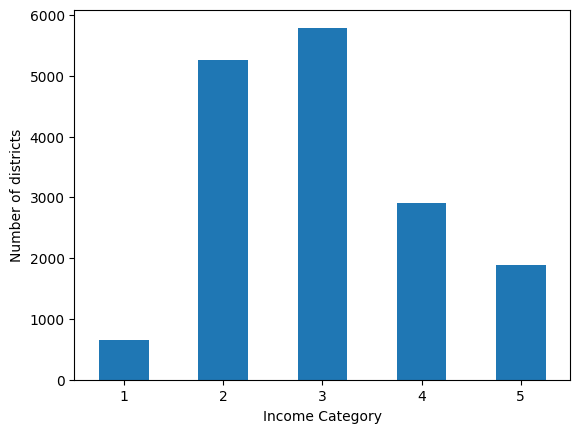

In [95]:
train_data['income_cat'].value_counts().sort_index().plot.bar(rot=0)
plt.xlabel('Income Category')
plt.ylabel('Number of districts')
plt.show()


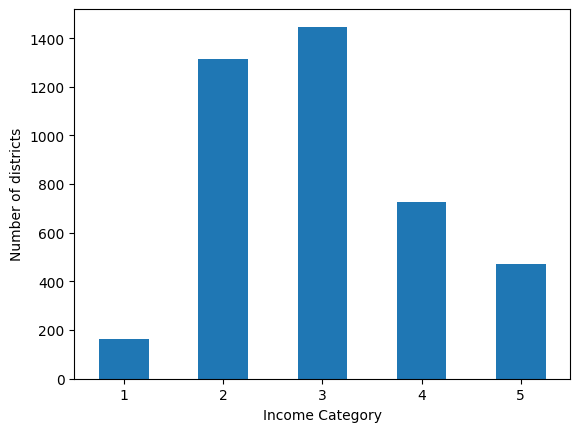

In [96]:
test_data['income_cat'].value_counts().sort_index().plot.bar(rot=0)
plt.xlabel('Income Category')
plt.ylabel('Number of districts')
plt.show()

Exploration: Now we are going to try a bunch of different transformations on the data (copies) to see how the model is going to learn best

In [97]:
housing = train_data.copy()


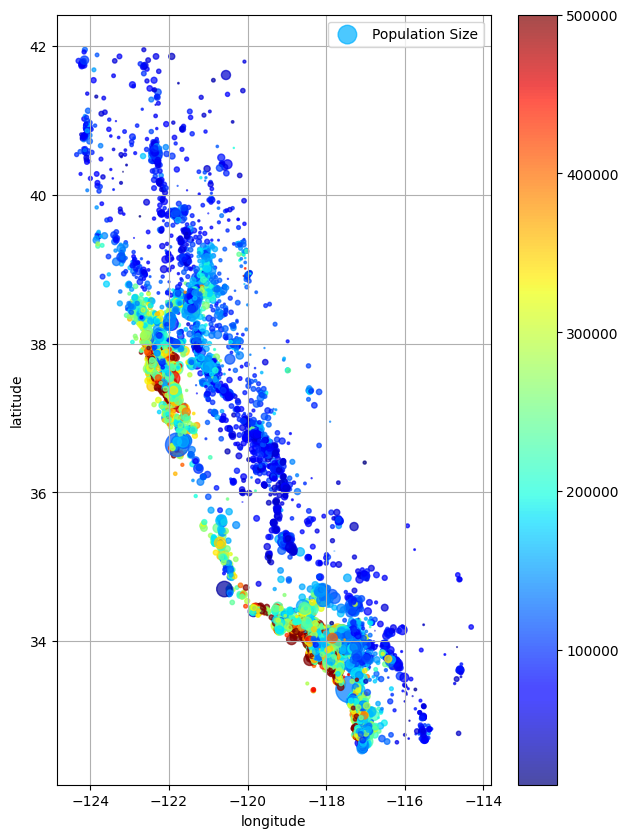

In [98]:
#creating scatter plot of the lat/lon for locations
housing.plot(kind='scatter',x='longitude',y='latitude',
             s=housing['population']/100, label='Population Size', c=housing['median_house_value'], cmap='jet',
             figsize=(7,10),grid=True,alpha=0.7,colorbar=True,legend=True)
plt.show()

Lets check the correlation of the data. It will show us whether one of the column's values being above its median is also followed by another coliumn being above/below its median on average from -1 to 1 scale.

In [99]:
corr_matrix = housing.corr(numeric_only=True)
corr_matrix

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.925165,-0.103132,0.040225,0.064313,0.096272,0.052611,-0.011798,-0.042619
latitude,-0.925165,1.000000,0.005802,-0.032872,-0.063882,-0.105898,-0.068911,-0.080681,-0.146498
housing_median_age,-0.103132,0.005802,1.000000,-0.360478,-0.321806,-0.294163,-0.304809,-0.115628,0.107145
total_rooms,0.040225,-0.032872,-0.360478,1.000000,0.929803,0.856973,0.918334,0.200559,0.139097
total_bedrooms,0.064313,-0.063882,-0.321806,0.929803,1.000000,0.878191,0.980566,-0.005729,0.055304
population,0.096272,-0.105898,-0.294163,0.856973,0.878191,1.000000,0.906532,0.007147,-0.019809
households,0.052611,-0.068911,-0.304809,0.918334,0.980566,0.906532,1.000000,0.013703,0.069976
median_income,-0.011798,-0.080681,-0.115628,0.200559,-0.005729,0.007147,0.013703,1.000000,0.687688
median_house_value,-0.042619,-0.146498,0.107145,0.139097,0.055304,-0.019809,0.069976,0.687688,1.000000


In [100]:
#We really want to see any correlation between the median price and the other cols
corr_matrix['median_house_value'].sort_values(ascending=False)
#Shows the as the house value goes above median, the median_income does too which makes sense. It goes up to .68 so quite a lot.

,median_house_value
median_house_value,1.000000
median_income,0.687688
total_rooms,0.139097
housing_median_age,0.107145
households,0.069976
total_bedrooms,0.055304
population,-0.019809
longitude,-0.042619
latitude,-0.146498


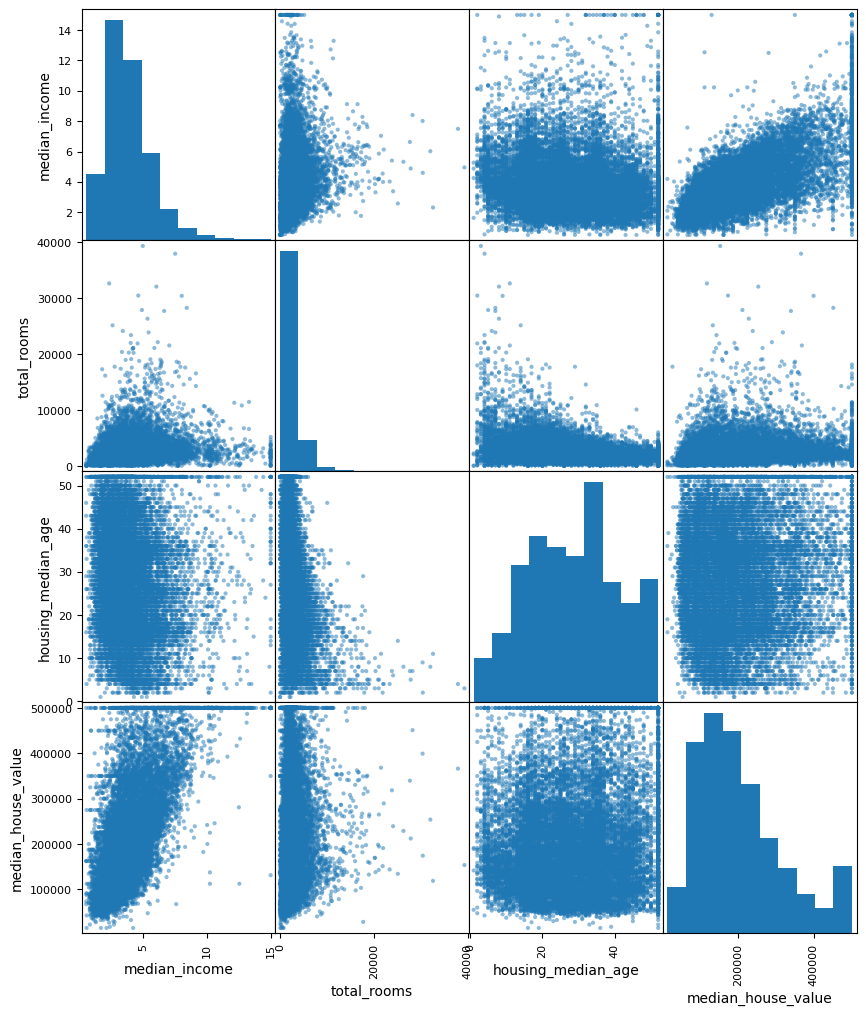

In [101]:
from pandas.plotting import scatter_matrix
chosen = ['median_income','total_rooms', 'housing_median_age','median_house_value']
scatter_matrix(housing[chosen], figsize=(10,12))
plt.show()

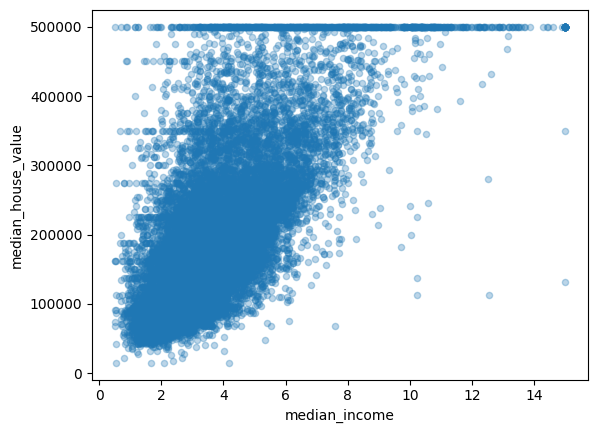

In [102]:
#lets take a look into the relationship between median income and house value because it seems to go up the most relationship wise
housing.plot(kind='scatter', x='median_income',y='median_house_value',alpha=0.3)
plt.show()

Lets now try to create new combinations of columns to see if we can find good correlation to the median value.

In [103]:

housing['bedroom_ratio'] = housing['total_bedrooms'] / housing['total_rooms']
housing['ppl_per_house'] = housing['population'] / housing['households']
housing['rooms_per_house'] = housing['total_rooms'] / housing['households']


In [104]:
#re-do the correlation testing to see if any new relationships compared to the value
corr_matrix = housing.corr(numeric_only=True)
corr_matrix['median_house_value'].sort_values(ascending=False)
#we can see now that as the price goes up, the bedroom to room ratio goes down and the rooms per house goes up with total_rooms

,median_house_value
median_house_value,1.000000
median_income,0.687688
rooms_per_house,0.160415
total_rooms,0.139097
housing_median_age,0.107145
households,0.069976
total_bedrooms,0.055304
population,-0.019809
ppl_per_house,-0.021863
longitude,-0.042619


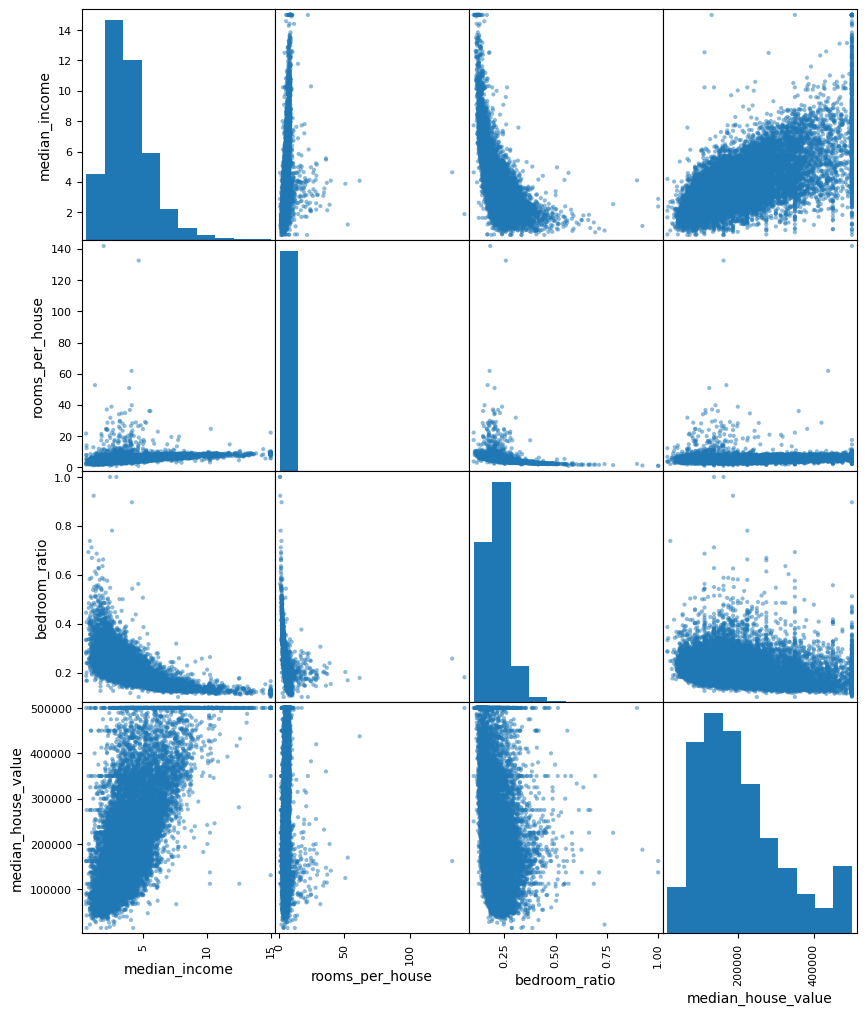

In [105]:
chosen = ['median_income','rooms_per_house','bedroom_ratio','median_house_value']
corr_matrix = scatter_matrix(housing[chosen], figsize=(10,12))
plt.show()

Now to prepare the data for our ML models, we need to seperate our features from our label

In [106]:
housing_features = train_data.drop('median_house_value',axis=1)
housing_labels = train_data['median_house_value'].copy()
housing_features.isna().sum() #we can see there are na vals for total bedrooms so we need to create a transformer to replace na vals

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,165
population,0
households,0
median_income,0
ocean_proximity,0
income_cat,0


Going to create a transformer to learn the median of the numerical cols in our data set so we can use it to replace the na values. We are using the SimpleImputer transformer, it can learn mean, median, most_frequent, or constant you set.
Also, a transformer is an object that learns from a data set and then uses what it learned to change the values in another data set.

In [107]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')


In [108]:
#Since it is a median transformer, we need to create a dataset of only the numerical columns
housing_numeric_cols = housing_features.select_dtypes(include=[np.number])
#fit our transformer using this data-- it will store a array of median of each column by learning the values
imputer.fit(housing_numeric_cols)
X = imputer.transform(housing_numeric_cols) #transformed the dataset to no null vals now, it returns a matrix so we need to build the dataframe again


In [109]:
#now we need to create the dataframe again
numeric_tr = pd.DataFrame(X, columns=housing_numeric_cols.columns, index=housing_numeric_cols.index)
numeric_tr.info() #now the data set has no na values

<class 'pandas.core.frame.DataFrame'>
Index: 16512 entries, 13314 to 16465
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           16512 non-null  float64
 1   latitude            16512 non-null  float64
 2   housing_median_age  16512 non-null  float64
 3   total_rooms         16512 non-null  float64
 4   total_bedrooms      16512 non-null  float64
 5   population          16512 non-null  float64
 6   households          16512 non-null  float64
 7   median_income       16512 non-null  float64
dtypes: float64(8)
memory usage: 1.1 MB


Now we need to create a transformer for categorical columns becuase models only want to deal with numerical data. Use OneHotEncoder for this, it will map to a sparse matrix and it turns it into a bunch of 0/1 values

In [110]:
#create the transformer
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder()
#create our categorical matrix using the ocean_proximity col
housing_cat = housing[['ocean_proximity']]


In [111]:
#fit(learn from our data) and transform our data into categorical
training_cat = encoder.fit_transform(housing_cat)
#create the dataframe
df_op = pd.DataFrame(training_cat.toarray(), columns=encoder.get_feature_names_out(), index=train_data.index)
df_op.head()

,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
13314,1.0,0.0,0.0,0.0,0.0
14853,1.0,0.0,0.0,0.0,0.0
5876,0.0,1.0,0.0,0.0,0.0
2413,0.0,1.0,0.0,0.0,0.0
16387,0.0,1.0,0.0,0.0,0.0


Now we are going to scale the data becuase it needs to be scaled to use regression properly and also check to see if we can make it more of a normal curve with the log properties

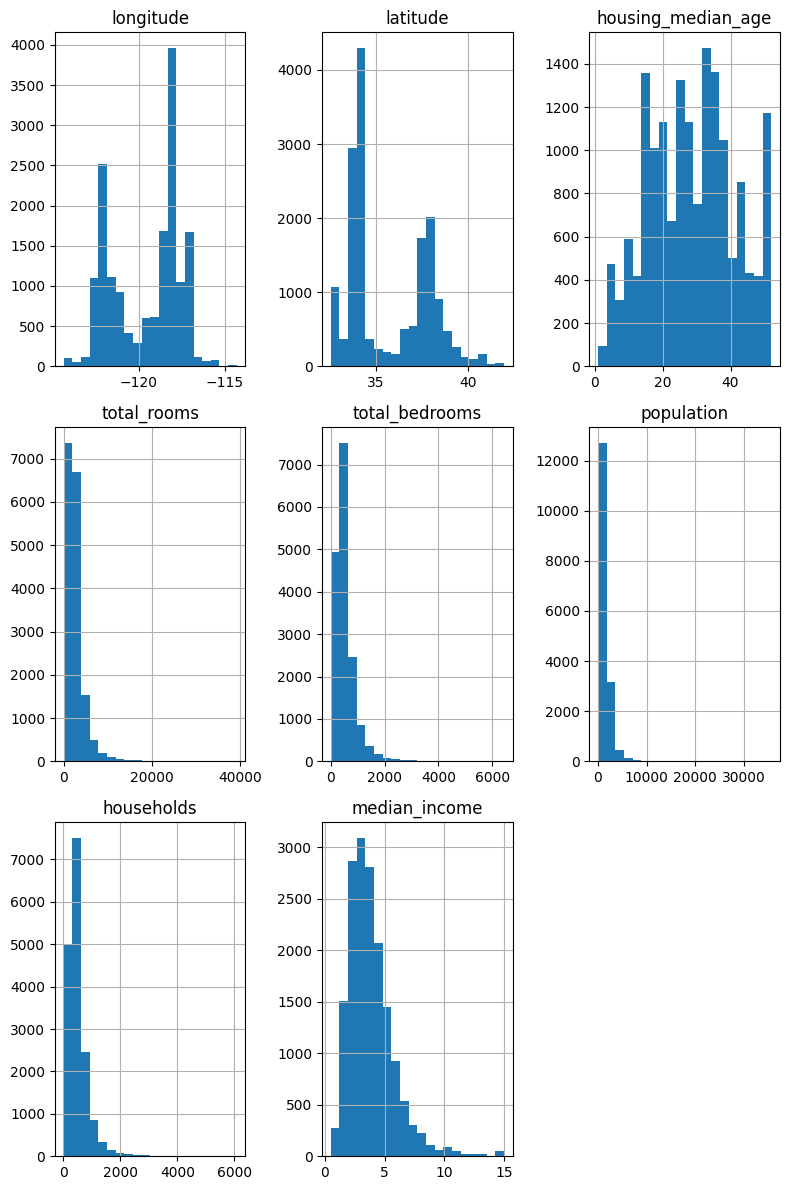

In [112]:
numeric_tr.hist(bins=20, figsize=(8,12))
plt.tight_layout()
plt.show()

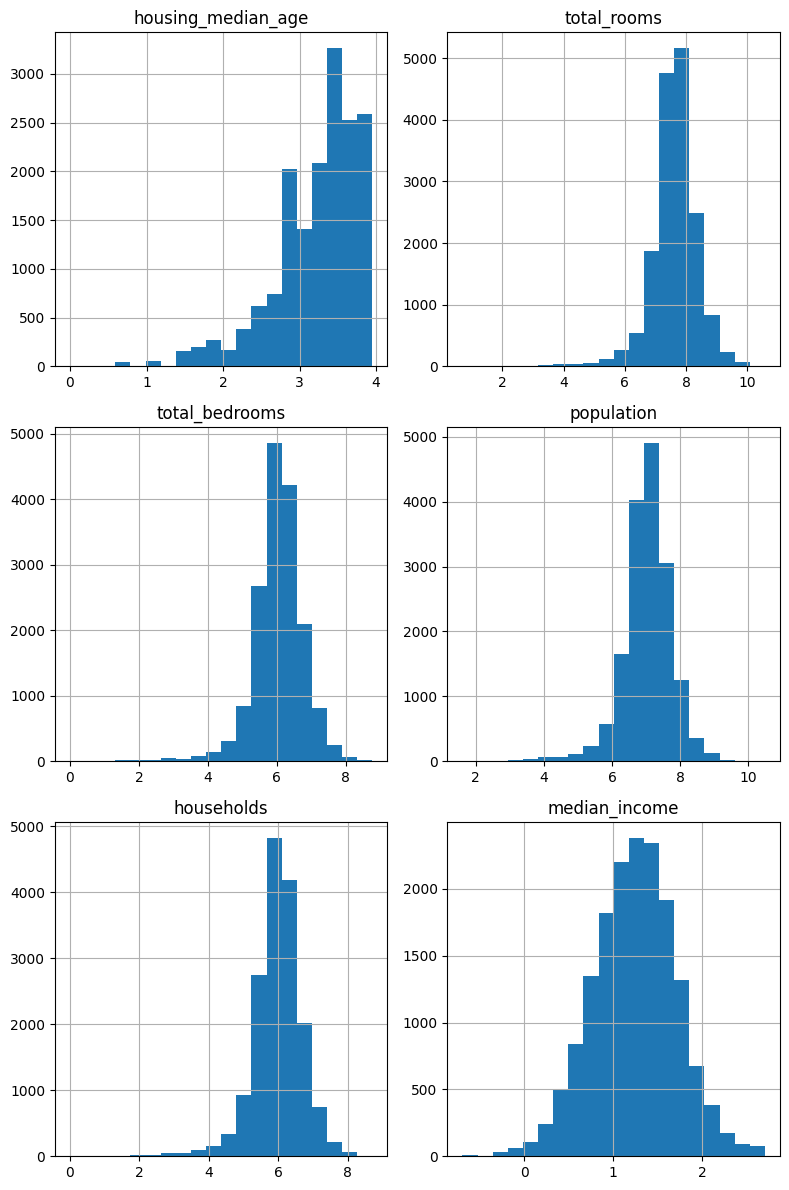

In [113]:
#applying log to each of them using FunctionTransform-- doesnt really learn with fit since its just log
from sklearn.preprocessing import FunctionTransformer
log_transform = FunctionTransformer(np.log)
log_features = log_transform.fit_transform(numeric_tr[['housing_median_age','total_rooms','total_bedrooms','population','households','median_income']])
log_features.hist(bins=20, figsize=(8,12))
plt.tight_layout()
plt.show()



In [114]:
#now lets use StandardScalar to scale all of the numeric values in the same range by converting to z-scores using the StandardScalar transformer
#it learens the trainig mean and std and applies to all the other values for their score
from sklearn.preprocessing import StandardScaler
scalar = StandardScaler()
scaled_training = scalar.fit_transform(numeric_tr)
new_training_df = pd.DataFrame(scaled_training, columns=numeric_tr.columns, index=numeric_tr.index)
new_training_df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
count,1.651200e+04,1.651200e+04,1.651200e+04,1.651200e+04,1.651200e+04,1.651200e+04,1.651200e+04,1.651200e+04
mean,3.246649e-15,1.159387e-15,2.189248e-17,-5.260650e-17,-1.974088e-17,3.797565e-17,-1.699760e-17,-1.049978e-16
std,1.000030e+00,1.000030e+00,1.000030e+00,1.000030e+00,1.000030e+00,1.000030e+00,1.000030e+00,1.000030e+00
min,-2.393008e+00,-1.444319e+00,-2.196947e+00,-1.205061e+00,-1.279216e+00,-1.246189e+00,-1.306621e+00,-1.765672e+00
25%,-1.112530e+00,-7.893724e-01,-8.477571e-01,-5.437784e-01,-5.715250e-01,-5.580039e-01,-5.775313e-01,-6.868456e-01
50%,5.430876e-01,-6.443485e-01,2.524829e-02,-2.323978e-01,-2.415882e-01,-2.305894e-01,-2.365901e-01,-1.767751e-01
75%,7.781753e-01,9.743054e-01,6.601613e-01,2.359342e-01,2.509263e-01,2.636047e-01,2.721991e-01,4.535036e-01
max,2.628866e+00,2.957858e+00,1.850623e+00,1.682566e+01,1.412740e+01,3.007062e+01,1.464156e+01,5.818542e+00


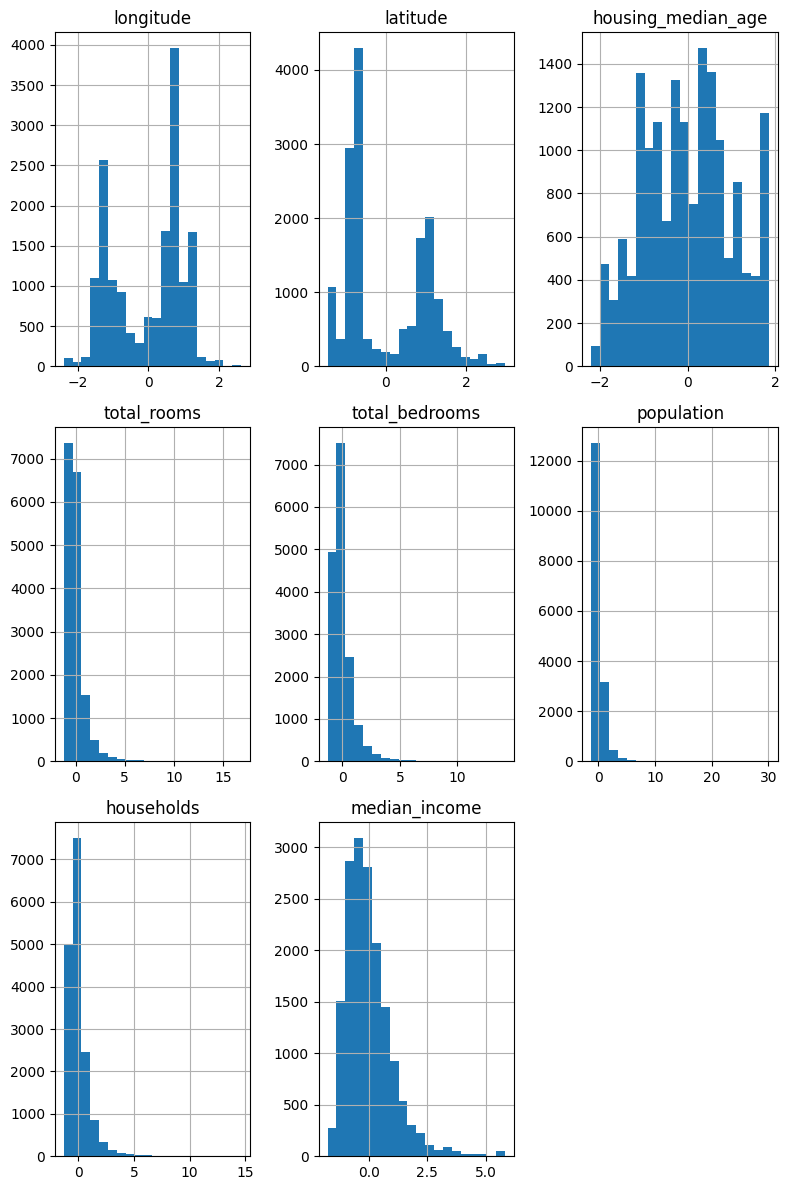

In [115]:
#now lets look at the histograms-- note, I did not use the scalar on the log normals
new_training_df.hist(bins=20, figsize=(8,12))
plt.tight_layout()
plt.show()

Lets make a custom transformer that is going to create new columns based on the args that are passed into the transformer

In [116]:
def create_col(X, numerator, denominator, name):
  X = X.copy()
  X[name] = X[[numerator]].values / X[[denominator]].values
  return X
add_room_ratio = FunctionTransformer(create_col, kw_args={'numerator':'total_rooms', 'denominator':'households','name':'rooms_per_house'})

In [117]:
#using this custom transformer to transform our training data
new_tr = add_room_ratio.transform(new_training_df)
#checking to see if there is a correlation in the rise of the rooms ratio as it increases above its median do other cols increase above its median
corr_matrix = new_tr.corr(numeric_only=True)
corr_matrix['rooms_per_house'].sort_values(ascending=False)

,rooms_per_house
rooms_per_house,1.000000e+00
housing_median_age,8.632583e-03
total_rooms,1.026067e-03
total_bedrooms,9.478558e-04
latitude,6.547056e-04
households,-3.466149e-18
population,-1.950494e-03
longitude,-2.461519e-03
median_income,-1.493285e-02


Now lets create a pipeline to transform the raw training data into pre-processed data that is ready to be fed into the model. Pre-processed data is going to be non-na, scaled, encoded(objects), normalized-ish, feature engineered(add couple columns)

In [118]:
X_train, X_test = train_data.drop('median_house_value', axis=1), train_data[['median_house_value']]
X_train.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
count,16512.000000,16512.000000,16512.000000,16512.000000,16347.000000,16512.000000,16512.000000,16512.000000
mean,-119.565770,35.627346,28.681868,2629.769259,537.067046,1424.693980,499.211180,3.875675
std,1.999314,2.137643,12.600532,2180.677157,420.256445,1139.263015,381.308956,1.911950
min,-124.350000,32.540000,1.000000,2.000000,1.000000,5.000000,1.000000,0.499900
25%,-121.790000,33.940000,18.000000,1444.000000,295.000000,789.000000,279.000000,2.562500
50%,-118.480000,34.250000,29.000000,2123.000000,435.000000,1162.000000,409.000000,3.537700
75%,-118.010000,37.710000,37.000000,3144.250000,644.000000,1725.000000,603.000000,4.742725
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100


Looking at the summary stats and info we can see we need to transform the data into all numerical(one object col), there are some na vals, need to scale because there are wide range of scales (age vs population)

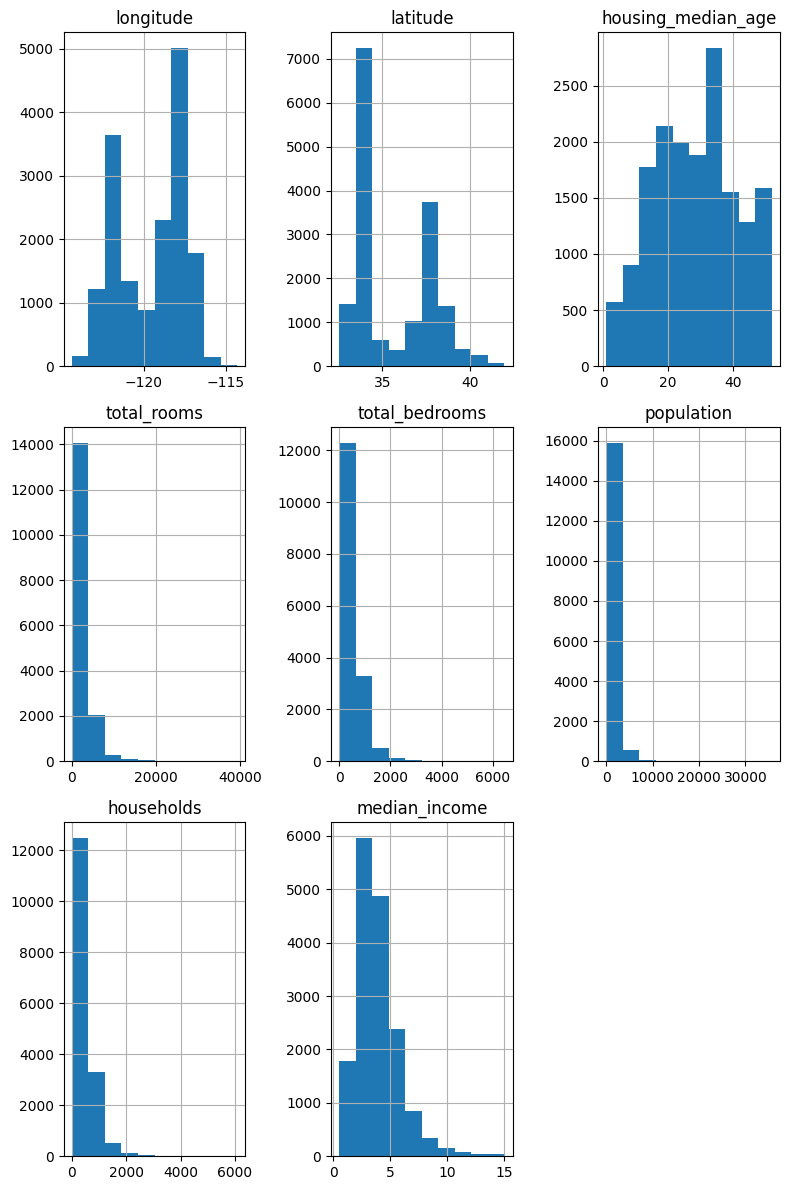

In [119]:
X_train.hist(figsize=(8,12))
plt.tight_layout()
plt.show()

For normalizing(log transformation), total_rooms, total_bedrooms, population, households, median_income.


In [120]:
from sklearn.preprocessing import FunctionTransformer
#create transformer for log transforms
log_transform = FunctionTransformer(np.log, feature_names_out='one-to-one')


In [121]:
#pipeline for log
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

log_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('log', log_transform),
    ('scale', StandardScaler()),
])

In [122]:
#pipelines for categorical data-- replace na with most frequent, encode to 0/1 for model
from sklearn.preprocessing import OneHotEncoder
cat_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore'))
])

In [123]:
#need a leftover pipeline for the rest of the cols-- theyre numerical so we jsut wanna impute and scale
left_over_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])

In [124]:
#pipeline for created columns-- the ratios. impute, compute, scale
#need a function returing a pipeline because it's used in each new col pipeline in the column_transform ending
#also computing the ratio takes in a 2d array because it comes after the impute step to ensure there are no missing values
def column_ratio(X):
  return X[:, [0]] / X[:,[1]]
def ratio_name(function_transformer, feature_names_in):
    return ["ratio"]
ratio_transform = FunctionTransformer(column_ratio, feature_names_out=ratio_name)
def ratio_pipeline():
  return Pipeline([
      ('impute', SimpleImputer(strategy='median')),
      ('compute_ratio', ratio_transform),
      ('scale', StandardScaler())
  ])

In [125]:
#now we need to combine these into a big pipeline specifying which columns for each
from sklearn.compose import ColumnTransformer
pre_processing = ColumnTransformer([
    ('bedrooms_per_house', ratio_pipeline(), ['total_bedrooms', 'total_rooms']),
    ('rooms_per_house', ratio_pipeline(),['total_rooms','households']),
    ('people_per_house', ratio_pipeline(), ['population','households']),
    ('categorical', cat_pipeline, ['ocean_proximity']),
    ('log', log_pipeline,['total_rooms', 'total_bedrooms', 'population', 'households', 'median_income'])
], remainder=left_over_pipeline)
pre_processing.fit(X_train)
train_transformed = pd.DataFrame(pre_processing.transform(X_train),columns=pre_processing.get_feature_names_out(), index=X_train.index)
train_transformed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 16512 entries, 13314 to 16465
Data columns (total 17 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   bedrooms_per_house__ratio                16512 non-null  float64
 1   rooms_per_house__ratio                   16512 non-null  float64
 2   people_per_house__ratio                  16512 non-null  float64
 3   categorical__ocean_proximity_<1H OCEAN   16512 non-null  float64
 4   categorical__ocean_proximity_INLAND      16512 non-null  float64
 5   categorical__ocean_proximity_ISLAND      16512 non-null  float64
 6   categorical__ocean_proximity_NEAR BAY    16512 non-null  float64
 7   categorical__ocean_proximity_NEAR OCEAN  16512 non-null  float64
 8   log__total_rooms                         16512 non-null  float64
 9   log__total_bedrooms                      16512 non-null  float64
 10  log__population                          16512 

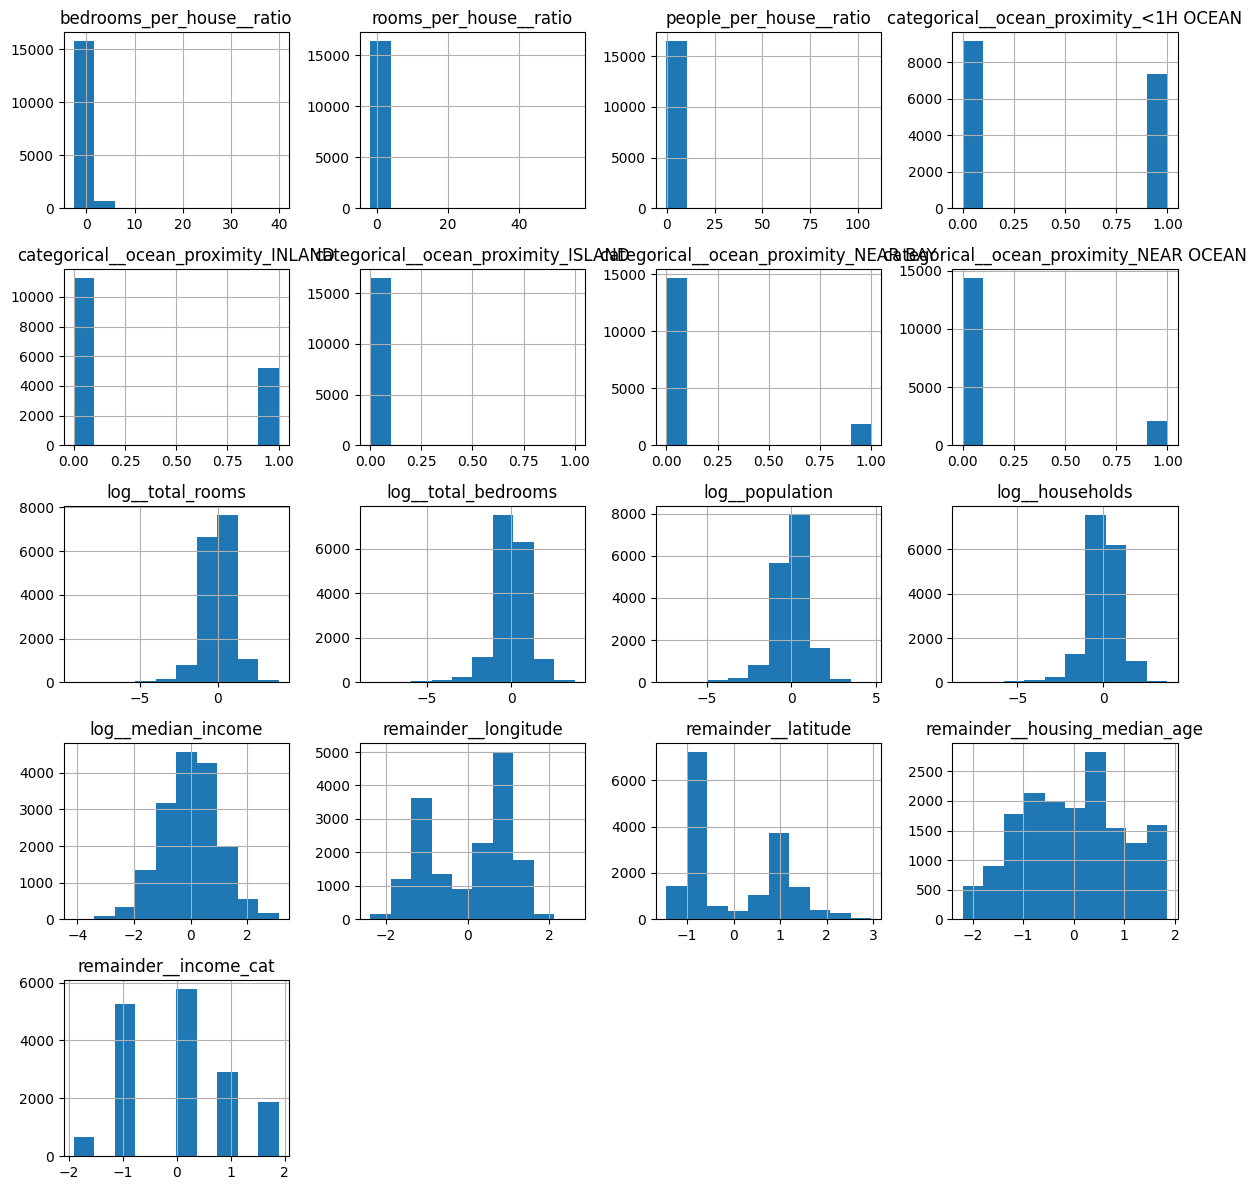

In [126]:
train_transformed.hist(figsize=(12,12))
plt.tight_layout()
plt.show()

Now we are going to create a predictor pipeline using a model of our choosing. It will take in the pre-processing pipeline and the model, when we call fit or predict the pipeline is first going to run the full pre-process pipeline and pass that data in as the X in the model and then the model runs from there

In [127]:
#using linear regression
from sklearn.linear_model import LinearRegression

lin_reg = Pipeline([
    ('pre_process', pre_processing),
    ('model', LinearRegression())
])
lin_reg.fit(X_train, housing_labels)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('pre_process',
                 ColumnTransformer(remainder=Pipeline(steps=[('impute',
                                                              SimpleImputer(strategy='median')),
                                                             ('scale',
                                                              StandardScaler())]),
                                   transformers=[('bedrooms_per_house',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('compute_ratio',
                                                                   FunctionTransformer(feature_names_out=<function ratio_name at 0x7eeff2cc4a40>,
                                                                                       func=<function...
                                                                  ('encode',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['ocean_proximity']),
                                                 ('log',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('log',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<ufunc 'log'>)),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['total_rooms',
                                                   'total_bedrooms',
                                                   'population', 'households',
                                                   'median_income'])])),
                ('model', LinearRegression())])

In [128]:
#now we run it using the training data and evaluate
from sklearn.metrics import root_mean_squared_error #using RMSE-- the root of the avg squared error, punishes bigger errors(misses)

training_results = lin_reg.predict(X_train)
RMSE = root_mean_squared_error(y_true=housing_labels,y_pred= training_results)
RMSE #not great-- its $70125 off per prediction on avg




70125.03758817993

Since our RMSE using linear regression was not great, we will use a more powerful model in DecisionTreeRegressor to better fit the data

In [129]:
from sklearn.tree import DecisionTreeRegressor

tree_pipeline = Pipeline([
    ('pre_process', pre_processing),
    ('tree', DecisionTreeRegressor(random_state=42))
])
tree_pipeline.fit(X_train, housing_labels)
result_tree = tree_pipeline.predict(X_train)
tree_RMSE = root_mean_squared_error(y_true=housing_labels, y_pred=result_tree)
tree_RMSE #we got a 0 RMSE which means it performed "perfectly" and got no predictions wrong however this is prolly overfitting-- mapping directly to the data


0.0

To test if it overfitted the data we are going to use k-fold cross validation because it will run the model freshly on k different folds to test on data it has not seen before while training on teh other k-1 folds.

In [130]:
from sklearn.model_selection import cross_val_score

cv_scores_lin = -cross_val_score(lin_reg, X_train, housing_labels, scoring='neg_root_mean_squared_error',cv=10)
np.mean(cv_scores)

np.float64(71293.1130790949)

In [131]:
cv_tree = -cross_val_score(tree_pipeline, X_train, housing_labels, scoring='neg_root_mean_squared_error', cv=10)
np.mean(cv_tree)
np.std(cv_tree) #as we can see the tree alg was actually pretty close to regression on the data it has not seen so it was overfitting the training data before

np.float64(2119.0054190799337)

In [132]:
from sklearn.ensemble import RandomForestRegressor

forest_pipeline = Pipeline([
    ('pre_process', pre_processing),
    ('model', RandomForestRegressor(random_state=42))
])
cv_forest = -cross_val_score(forest_pipeline, X_train, housing_labels, scoring='neg_root_mean_squared_error', cv=10)
pd.Series(cv_forest).describe()

,0
count,10.000000
mean,49684.893580
std,865.739822
min,48014.444010
25%,49304.428637
50%,49649.401756
75%,50073.830710
max,51080.397241


Now that we have a better rmse score for  the cross validation I am going to use this model on the test data set.

In [144]:
forest_pipeline.fit(X_train, np.ravel(X_test))
test_feed = test_data.drop('median_house_value', axis=1)
test_labels = test_data['median_house_value'].copy()
res = forest_pipeline.predict(test_feed)
rmse = root_mean_squared_error(y_pred=res, y_true=test_labels)



KeyboardInterrupt: 

In [145]:
rmse

49748.915374146534

As we can see, we got a good model without even performing tuning on the hyperparameters. It performed well on our test set with an avg error of aroud $49,748.